
# YOLO26s — Cashew Disease Detection

**Experiment:** `EXP-Y26S-SMALL-009` — chạy mới từ epoch 0 với `yolo26s.pt` pretrained; không resume từ EXP-008.

**Dataset:** [Test_400image_V6.v1i.yolo26.zip](https://drive.google.com/file/d/1WGwaWJfFNFK8a3Po6GdjHuxFizXfYvwI/view) trong [thư mục 400 image v6](https://drive.google.com/drive/folders/15uD5GXP9HcCRsigof-GGlub4pgJKfmMx). ZIP kết quả sẽ được upload về cùng thư mục.

Notebook này dùng để:

- tải và giải nén dataset YOLO26 từ Google Drive hoặc Kaggle Input;
- kiểm tra cấu trúc Train / Validation / Test;
- thống kê số ảnh và số bounding box theo từng class;
- huấn luyện `YOLO26s`;
- load checkpoint `best.pt`;
- đánh giá trên **Test set**;
- xuất các chỉ số:
  - Precision
  - Recall
  - F1-score
  - mAP@0.50
  - mAP@0.75
  - mAP@0.50:0.95
  - AP theo từng class
  - Mean IoU / Median IoU của các prediction match đúng
  - TP / FP / FN
  - Thời gian huấn luyện (giây và phút)
- lưu confusion matrix, PR curve, F1 curve và prediction mẫu;
- đóng gói toàn bộ kết quả thành ZIP và upload trực tiếp lên Google Drive.

> **Lưu ý nghiên cứu:** Validation dùng để theo dõi/chọn checkpoint. Test chỉ nên dùng để đánh giá cuối cùng, không dùng để chỉnh learning rate, augmentation, epochs hoặc các hyperparameter khác.


## 01. Cài thư viện

Chạy notebook trên **Colab** hoặc **Kaggle** với GPU. Trên Colab, chọn `Runtime → Change runtime type → GPU`; trên Kaggle, chọn `Settings → Accelerator → GPU`.


In [1]:
# Cài thư viện YOLO và Google Drive API (chạy trước các cell import)
!pip install -q -U ultralytics google-api-python-client google-auth pyyaml


## 02. Import & kiểm tra môi trường

In [2]:

import os
import sys
import json
import glob
import hashlib
import time
import random
import shutil
import zipfile
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

MATRIX_CMAP = LinearSegmentedColormap.from_list(
    "readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)
from PIL import Image, ImageDraw

import torch
import yaml
import ultralytics
import google.auth
from ultralytics import YOLO

try:
    import google.colab  # Google Colab runtime
    RUNTIME = "Colab"
except ImportError:
    RUNTIME = "Kaggle" if Path("/kaggle/working").is_dir() else "Unknown"
if RUNTIME == "Unknown":
    raise RuntimeError("Notebook này hỗ trợ Colab hoặc Kaggle")

print("=" * 70)
print("ENVIRONMENT")
print("=" * 70)
print("Runtime     :", RUNTIME)
print("Python      :", sys.version.split()[0])
print("PyTorch     :", torch.__version__)
print("Ultralytics :", ultralytics.__version__)
print("CUDA        :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))
else:
    print("GPU         : Không có GPU - hãy bật GPU trong Kaggle Settings")


ENVIRONMENT
Runtime     : Colab
Python      : 3.13.16
PyTorch     : 2.11.0+cu130
Ultralytics : 8.4.192
CUDA        : True
GPU         : NVIDIA RTX PRO 6000 Blackwell Server Edition


## 03. Configuration

In [3]:

# ============================================================
# CONFIG
# ============================================================

EXPERIMENT_ID = "EXP-Y26S-SMALL-009"
SEED = 42

MODEL_NAME = "yolo26s.pt"

EPOCHS = 50
PATIENCE = 20
IMG_SIZE = 640
BATCH_SIZE = 8
WORKERS = 4

OPTIMIZER = "AdamW"
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 5e-4

# Augmentation nhẹ cho dataset nhỏ
MOSAIC = 0.5
MIXUP = 0.0
COPY_PASTE = 0.0
FLIPLR = 0.5

# Threshold chỉ dùng cho custom IoU analysis
PRED_CONF = 0.25
NMS_IOU = 0.70
MATCH_IOU = 0.50

DEVICE = 0 if torch.cuda.is_available() else "cpu"

# Dataset trên Google Drive
DRIVE_FILE_ID = "1WGwaWJfFNFK8a3Po6GdjHuxFizXfYvwI"
ZIP_FILENAME = "Test_400image_V6.v1i.yolo26.zip"
DRIVE_RESULT_FOLDER_ID = "15uD5GXP9HcCRsigof-GGlub4pgJKfmMx"
DATASET_ZIP_OVERRIDE = None  # Optional local ZIP path; must match Drive dataset MD5.

WORK_BASE = Path("/content") if RUNTIME == "Colab" else Path("/kaggle/working")
INPUT_ROOT = Path("/content/input") if RUNTIME == "Colab" else Path("/kaggle/input")
WORK_ROOT = WORK_BASE / "cashew_yolo26"
DATASET_DIR = WORK_ROOT / EXPERIMENT_ID / "dataset"
RUNS_DIR = WORK_ROOT / "runs"
EXPORT_DIR = WORK_ROOT / EXPERIMENT_ID / "export"

for p in [WORK_ROOT, RUNS_DIR, EXPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Experiment :", EXPERIMENT_ID)
print("Model      :", MODEL_NAME)
print("Device     :", DEVICE)
print("Image size :", IMG_SIZE)
print("Batch size :", BATCH_SIZE)


Experiment : EXP-Y26S-SMALL-009
Model      : yolo26s.pt
Device     : 0
Image size : 640
Batch size : 8


### 03a. Xác thực Drive và kiểm tra phiên bản dataset

Notebook chạy được trên **Colab** hoặc **Kaggle**. Trên Colab, cấp quyền Google khi hộp thoại xuất hiện; không cần `kaggle_secrets` hoặc mount Drive. Trên Kaggle, bật Internet và gắn secret `GOOGLE_DRIVE_OAUTH_JSON` theo hướng dẫn của notebook EXP-008.

Trước khi train, notebook kiểm tra file ZIP nguồn nằm trong [thư mục 400 image v6](https://drive.google.com/drive/folders/15uD5GXP9HcCRsigof-GGlub4pgJKfmMx) và tài khoản có quyền ghi vào thư mục đó. Kết quả cuối sẽ upload về chính thư mục này. File tạm được tạo trong `/content` (Colab) hoặc `/kaggle/working` (Kaggle).

Nếu xác thực hoặc quyền thư mục không đúng, notebook dừng **trước khi train**. Không đặt OAuth JSON vào notebook, dataset hay output.


In [4]:
# ============================================================
# DRIVE AUTH + DATASET VERSION PREFLIGHT
# ============================================================
from google.oauth2.credentials import Credentials
from google.auth.transport.requests import Request
from googleapiclient.discovery import build

try:
    if RUNTIME == "Colab":
        from google.colab import auth
        auth.authenticate_user()
        drive_credentials, _ = google.auth.default()
    else:
        from kaggle_secrets import UserSecretsClient
        credential_info = json.loads(UserSecretsClient().get_secret("GOOGLE_DRIVE_OAUTH_JSON"))
        if credential_info.get("type") != "authorized_user":
            raise ValueError("Secret phải là OAuth authorized_user JSON")
        drive_credentials = Credentials.from_authorized_user_info(
            credential_info, scopes=["https://www.googleapis.com/auth/drive"]
        )
        if not drive_credentials.valid:
            drive_credentials.refresh(Request())
    drive_service = build("drive", "v3", credentials=drive_credentials, cache_discovery=False)
    result_folder = drive_service.files().get(
        fileId=DRIVE_RESULT_FOLDER_ID,
        fields="id,name,mimeType,capabilities(canAddChildren)",
        supportsAllDrives=True,
    ).execute()
    dataset_metadata = drive_service.files().get(
        fileId=DRIVE_FILE_ID,
        fields="id,name,size,md5Checksum,parents,mimeType",
        supportsAllDrives=True,
    ).execute()
except Exception as exc:
    raise RuntimeError(
        "Không kết nối được Drive. Trên Colab hãy cấp quyền đúng tài khoản; "
        "trên Kaggle hãy bật Internet và gắn Secret GOOGLE_DRIVE_OAUTH_JSON."
    ) from exc

if result_folder.get("mimeType") != "application/vnd.google-apps.folder":
    raise ValueError("DRIVE_RESULT_FOLDER_ID không phải folder")
if not result_folder.get("capabilities", {}).get("canAddChildren", False):
    raise PermissionError("Tài khoản không có quyền ghi vào folder 400 image v6")
if dataset_metadata.get("name") != ZIP_FILENAME:
    raise ValueError(f"Dataset ZIP sai tên: {dataset_metadata.get('name')}")
if DRIVE_RESULT_FOLDER_ID not in dataset_metadata.get("parents", []):
    raise ValueError("Dataset ZIP không nằm trong folder 400 image v6")

print("Drive folder :", result_folder["name"], result_folder["id"])
print("Dataset ZIP  :", dataset_metadata["name"], dataset_metadata["size"], "bytes")


Drive folder : 400 image v6 15uD5GXP9HcCRsigof-GGlub4pgJKfmMx
Dataset ZIP  : Test_400image_V6.v1i.yolo26.zip 29547941 bytes


## 04. Tải và kiểm tra dataset V6

Notebook dùng đúng file ID đã kiểm tra ở cell trước. Nếu sử dụng bản ZIP trong input hoặc `DATASET_ZIP_OVERRIDE`, MD5 phải trùng bản trên Drive; không chọn nhầm dataset từ phiên bản khác.


In [5]:
# ============================================================
# DOWNLOAD / VERIFY / EXTRACT THE EXACT V6 DATASET
# ============================================================
from googleapiclient.http import MediaIoBaseDownload

def digest_file(path, algorithm="sha256"):
    h = hashlib.new(algorithm)
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

if DATASET_ZIP_OVERRIDE:
    ZIP_PATH = Path(DATASET_ZIP_OVERRIDE)
    if not ZIP_PATH.is_file():
        raise FileNotFoundError(f"DATASET_ZIP_OVERRIDE không tồn tại: {ZIP_PATH}")
else:
    input_zips = sorted(INPUT_ROOT.rglob(ZIP_FILENAME)) if INPUT_ROOT.is_dir() else []
    if len(input_zips) > 1:
        raise RuntimeError(f"Nhiều ZIP cùng tên trong input: {input_zips}")
    if input_zips:
        ZIP_PATH = input_zips[0]
    else:
        ZIP_PATH = WORK_ROOT / ZIP_FILENAME
        temp = ZIP_PATH.with_name(ZIP_PATH.name + ".partial")
        request = drive_service.files().get_media(fileId=DRIVE_FILE_ID, supportsAllDrives=True)
        with temp.open("wb") as stream:
            downloader = MediaIoBaseDownload(stream, request, chunksize=8 * 1024 * 1024)
            done = False
            while not done:
                status, done = downloader.next_chunk(num_retries=3)
                if status is not None:
                    print(f"Dataset download: {status.progress():.0%}")
        temp.replace(ZIP_PATH)

if ZIP_PATH.stat().st_size != int(dataset_metadata["size"]):
    raise ValueError("Dataset ZIP size không khớp file trên Drive")
if dataset_metadata.get("md5Checksum") and digest_file(ZIP_PATH, "md5") != dataset_metadata["md5Checksum"]:
    raise ValueError("Dataset ZIP MD5 không khớp file trên Drive")
if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError(f"File không phải ZIP hợp lệ: {ZIP_PATH}")
DATASET_SHA256 = digest_file(ZIP_PATH)

# Tách riêng dataset của EXP-009; không dùng cache của EXP-008.
if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)
DATASET_DIR.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH) as archive:
    root = DATASET_DIR.resolve()
    for member in archive.infolist():
        if not (DATASET_DIR / member.filename).resolve().is_relative_to(root):
            raise ValueError(f"Đường dẫn không an toàn trong ZIP: {member.filename}")
    archive.extractall(DATASET_DIR)

YAML_FILES = sorted(DATASET_DIR.rglob("data.yaml")) + sorted(DATASET_DIR.rglob("data.yml"))
if len(YAML_FILES) != 1:
    raise RuntimeError(f"Cần đúng một data.yaml/data.yml: {YAML_FILES}")
ORIGINAL_YAML = YAML_FILES[0]
DATASET_SOURCE_DIR = ORIGINAL_YAML.parent
dataset_source = {
    "drive_file_id": DRIVE_FILE_ID,
    "drive_folder_id": DRIVE_RESULT_FOLDER_ID,
    "zip_filename": ZIP_FILENAME,
    "zip_size_bytes": ZIP_PATH.stat().st_size,
    "zip_sha256": DATASET_SHA256,
    "zip_md5": digest_file(ZIP_PATH, "md5"),
}
(EXPORT_DIR / "dataset_source.json").write_text(
    json.dumps(dataset_source, indent=2), encoding="utf-8"
)
print("Dataset root:", DATASET_SOURCE_DIR)
print("Dataset SHA256:", DATASET_SHA256)


Dataset download: 28%
Dataset download: 57%
Dataset download: 85%
Dataset download: 100%
Dataset root: /content/cashew_yolo26/EXP-Y26S-SMALL-009/dataset/Test_400image_V6.v1i.yolo26
Dataset SHA256: fcd51e86c055178514caf34433d1adbaa2923e6871a20be445b7b5d1feb0a9ba


## 05. Giải nén dataset và chuẩn hóa `data.yaml`

In [6]:
# ============================================================
# 05. LOAD & FIX DATA.YAML
# ============================================================

import yaml

with open(ORIGINAL_YAML, "r", encoding="utf-8") as f:
    raw_cfg = yaml.safe_load(f)

print("Original data.yaml:")
print(raw_cfg)

Original data.yaml:
{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 3, 'names': ['anthracnose', 'leaf_miner', 'red_rust'], 'roboflow': {'workspace': 'nguyen-tien-tai-32hgs', 'project': 'test_400image_v6', 'version': 1, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/nguyen-tien-tai-32hgs/test_400image_v6/dataset/1'}}


In [7]:

# ============================================================
# FIX ROBOFLOW PATHS
# ============================================================

yaml_dir = ORIGINAL_YAML.parent.resolve()

def find_split(split):
    candidates = []

    if split == "train":
        raw = raw_cfg.get("train")
        fallback_names = ["train"]
    elif split == "val":
        raw = raw_cfg.get("val")
        fallback_names = ["valid", "val"]
    else:
        raw = raw_cfg.get("test")
        fallback_names = ["test"]

    if raw:
        raw_path = Path(str(raw))
        if raw_path.is_absolute():
            candidates.append(raw_path)
        else:
            candidates.append((yaml_dir / raw_path).resolve())

    for name in fallback_names:
        candidates.append((yaml_dir / name / "images").resolve())
        candidates.append((DATASET_DIR / name / "images").resolve())

    for p in candidates:
        if p.is_relative_to(DATASET_DIR.resolve()) and p.is_dir() and any(p.iterdir()) and (p.parent / "labels").is_dir():
            return p

    raise FileNotFoundError(f"Không tìm thấy split {split}. Đã thử: {candidates}")

TRAIN_IMAGES = find_split("train")
VAL_IMAGES = find_split("val")
TEST_IMAGES = find_split("test")

names = raw_cfg["names"]
if isinstance(names, dict):
    names = [names[i] if i in names else names[str(i)] for i in range(int(raw_cfg["nc"]))]
if len(names) != int(raw_cfg["nc"]):
    raise ValueError("Số class trong names và nc không khớp")

fixed_cfg = {
    "train": str(TRAIN_IMAGES),
    "val": str(VAL_IMAGES),
    "test": str(TEST_IMAGES),
    "nc": int(raw_cfg["nc"]),
    "names": names,
}

# Save the normalized YAML with this experiment
FIXED_YAML = WORK_ROOT / EXPERIMENT_ID / "data_fixed.yaml"

with open(FIXED_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        fixed_cfg,
        f,
        sort_keys=False,
        allow_unicode=True
    )

print("Fixed YAML :", FIXED_YAML)
print("Train      :", TRAIN_IMAGES)
print("Validation :", VAL_IMAGES)
print("Test       :", TEST_IMAGES)
print("Classes    :", fixed_cfg["names"])

with open(FIXED_YAML, "r", encoding="utf-8") as f:
    print("\n" + f.read())


Fixed YAML : /content/cashew_yolo26/EXP-Y26S-SMALL-009/data_fixed.yaml
Train      : /content/cashew_yolo26/EXP-Y26S-SMALL-009/dataset/Test_400image_V6.v1i.yolo26/train/images
Validation : /content/cashew_yolo26/EXP-Y26S-SMALL-009/dataset/Test_400image_V6.v1i.yolo26/valid/images
Test       : /content/cashew_yolo26/EXP-Y26S-SMALL-009/dataset/Test_400image_V6.v1i.yolo26/test/images
Classes    : ['anthracnose', 'leaf_miner', 'red_rust']

train: /content/cashew_yolo26/EXP-Y26S-SMALL-009/dataset/Test_400image_V6.v1i.yolo26/train/images
val: /content/cashew_yolo26/EXP-Y26S-SMALL-009/dataset/Test_400image_V6.v1i.yolo26/valid/images
test: /content/cashew_yolo26/EXP-Y26S-SMALL-009/dataset/Test_400image_V6.v1i.yolo26/test/images
nc: 3
names:
- anthracnose
- leaf_miner
- red_rust



## 06. Kiểm tra và thống kê dataset

,images,images_with_boxes,boxes,anthracnose,leaf_miner,red_rust
train,496,494,14261,3465,732,10064
val,80,80,2178,676,109,1393
test,39,39,1335,420,91,824


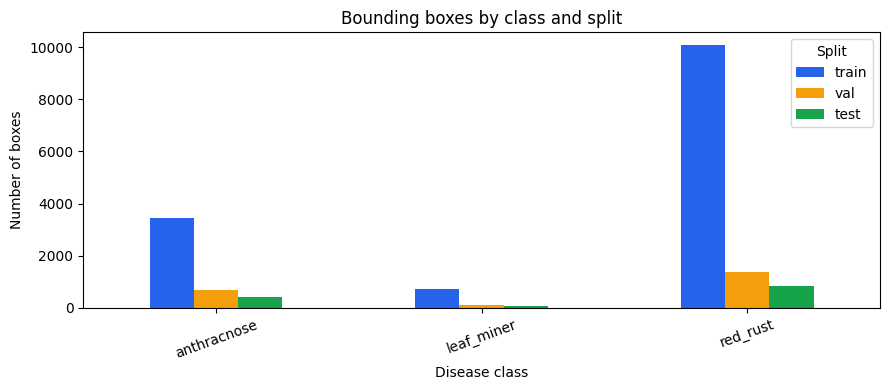

In [8]:

# ============================================================
# DATASET STATISTICS
# ============================================================

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def get_images(folder):
    return sorted([
        p for p in Path(folder).rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ])

def image_to_label_path(image_path):
    parts = list(image_path.parts)
    for i in range(len(parts) - 1, -1, -1):
        if parts[i] == "images":
            parts[i] = "labels"
            break
    return Path(*parts).with_suffix(".txt")

def split_stats(folder, class_names):
    images = get_images(folder)
    class_boxes = defaultdict(int)
    images_with_labels = 0
    total_boxes = 0

    for img in images:
        label_path = image_to_label_path(img)

        if not label_path.exists():
            continue

        text = label_path.read_text(encoding="utf-8").strip()

        if not text:
            continue

        images_with_labels += 1

        for line in text.splitlines():
            parts = line.split()

            if len(parts) >= 5:
                cls_id = int(float(parts[0]))
                class_boxes[cls_id] += 1
                total_boxes += 1

    row = {
        "images": len(images),
        "images_with_boxes": images_with_labels,
        "boxes": total_boxes,
    }

    for i, name in enumerate(class_names):
        row[name] = class_boxes[i]

    return row

class_names = fixed_cfg["names"]

stats = {
    "train": split_stats(TRAIN_IMAGES, class_names),
    "val": split_stats(VAL_IMAGES, class_names),
    "test": split_stats(TEST_IMAGES, class_names),
}

stats_df = pd.DataFrame(stats).T
display(stats_df)

stats_df.to_csv(EXPORT_DIR / "dataset_statistics.csv", index=True)

with open(EXPORT_DIR / "dataset_statistics.json", "w", encoding="utf-8") as f:
    json.dump(stats, f, indent=2, ensure_ascii=False)

# Distribution plot for dataset audit, not a significance test.
fig, ax = plt.subplots(figsize=(9, 4))
box_counts = stats_df[class_names].T
box_counts.plot(kind="bar", ax=ax, color=["#2563eb", "#f59e0b", "#16a34a"])
ax.set_title("Bounding boxes by class and split")
ax.set_ylabel("Number of boxes")
ax.set_xlabel("Disease class")
ax.legend(title="Split")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(EXPORT_DIR / "class_box_distribution.png", dpi=180)
plt.show()



### Kiểm tra nhanh annotation

Cell dưới hiển thị một số ảnh Train cùng bounding box ground-truth để đảm bảo annotation đọc đúng.


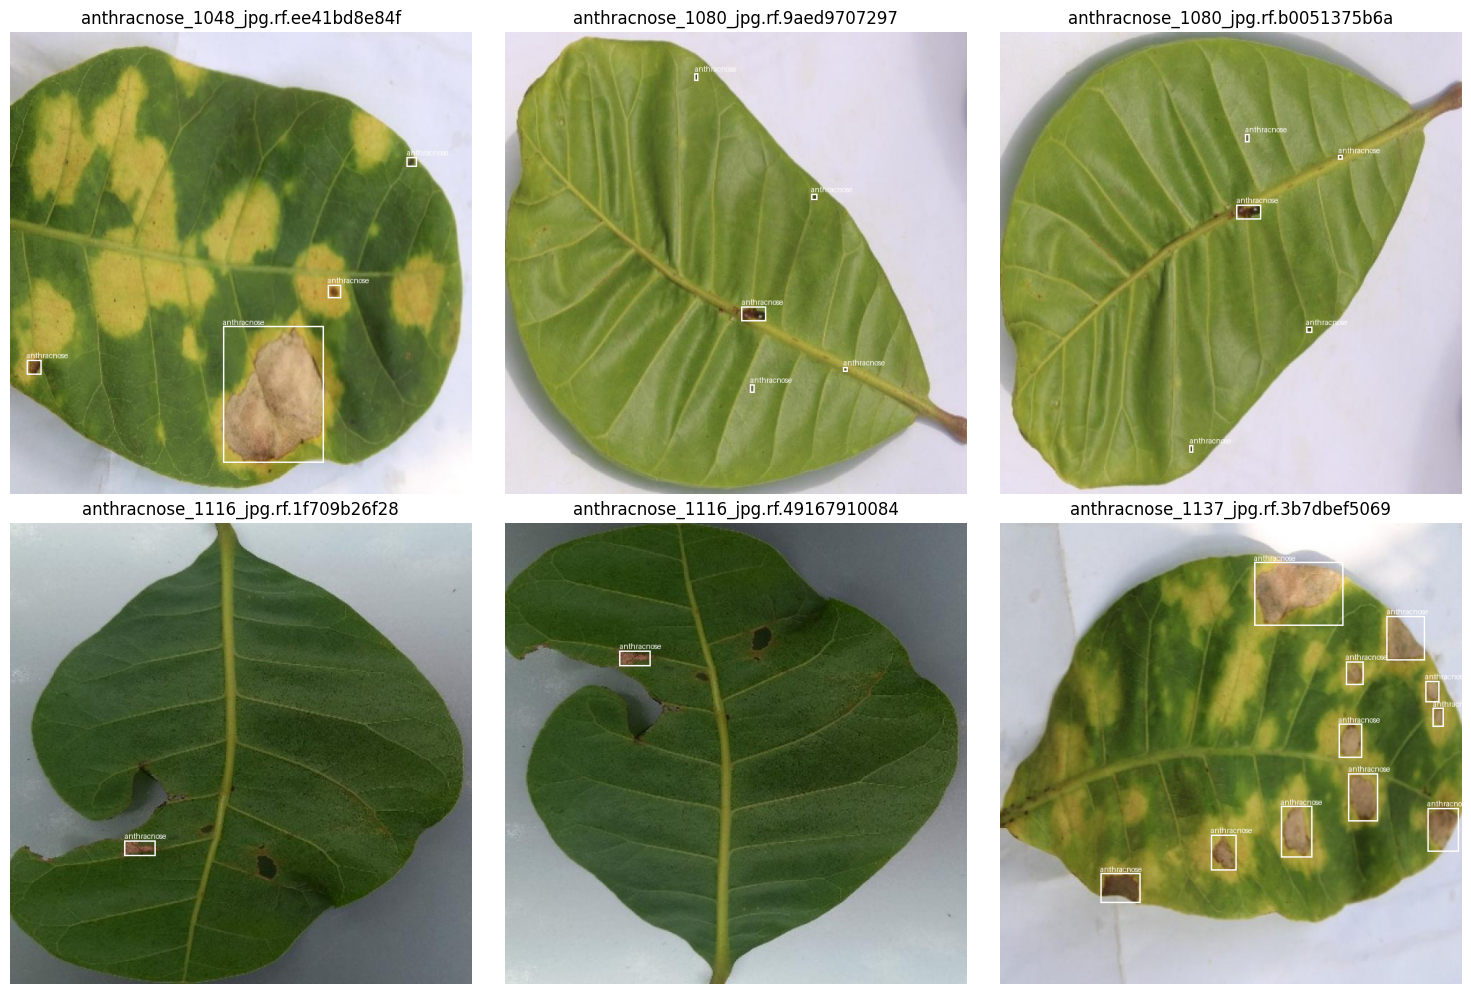

In [9]:

def yolo_xywhn_to_xyxy(xc, yc, w, h, img_w, img_h):
    xc, yc = xc * img_w, yc * img_h
    w, h = w * img_w, h * img_h
    return (
        xc - w / 2,
        yc - h / 2,
        xc + w / 2,
        yc + h / 2
    )

sample_images = get_images(TRAIN_IMAGES)[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for ax, img_path in zip(axes, sample_images):
    img = Image.open(img_path).convert("RGB")
    draw = ImageDraw.Draw(img)

    label_path = image_to_label_path(img_path)

    if label_path.exists():
        for line in label_path.read_text().strip().splitlines():
            parts = line.split()
            if len(parts) < 5:
                continue

            cls_id = int(float(parts[0]))
            xc, yc, w, h = map(float, parts[1:5])
            box = yolo_xywhn_to_xyxy(xc, yc, w, h, img.width, img.height)

            draw.rectangle(box, width=2)
            draw.text((box[0], max(0, box[1] - 12)), class_names[cls_id])

    ax.imshow(img)
    ax.axis("off")
    ax.set_title(img_path.name[:35])

plt.tight_layout()
plt.show()


## 07. Khởi tạo YOLO26s

Mỗi experiment bắt đầu lại từ epoch 0 bằng checkpoint pretrained `yolo26s.pt`. EXP-009 không nạp `best.pt` hoặc `last.pt` của EXP-008, không bật `resume`.


In [10]:

model = YOLO(MODEL_NAME)
print(model)


YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C3k2(
        (cv1): Conv(
          (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(96, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(128, eps=0.001, momentum=0.03, affine=True, track_runnin

## 08. Huấn luyện YOLO26s

In [11]:

# ============================================================
# TRAIN
# ============================================================

TRAIN_RUN_EXPECTED = RUNS_DIR / "train" / EXPERIMENT_ID
if TRAIN_RUN_EXPECTED.exists():
    raise RuntimeError(
        f"Run {EXPERIMENT_ID} đã tồn tại tại {TRAIN_RUN_EXPECTED}. "
        "Để train mới từ epoch 0, dùng runtime mới hoặc EXPERIMENT_ID mới."
    )
train_start = time.perf_counter()

train_results = model.train(
    data=str(FIXED_YAML),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,

    optimizer=OPTIMIZER,
    lr0=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,

    mosaic=MOSAIC,
    mixup=MIXUP,
    copy_paste=COPY_PASTE,
    fliplr=FLIPLR,

    seed=SEED,
    deterministic=True,

    project=str(RUNS_DIR / "train"),
    name=EXPERIMENT_ID,
    exist_ok=False,

    plots=True,
    save=True,
    verbose=True,
)

training_time = time.perf_counter() - train_start

print(f"\nTraining time: {training_time:.1f} seconds ({training_time / 60:.2f} minutes)")


Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cashew_yolo26/EXP-Y26S-SMALL-009/data_fixed.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, 

## 09. Xác định `best.pt` và xem learning curves

Best checkpoint: /content/cashew_yolo26/runs/train/EXP-Y26S-SMALL-009/weights/best.pt
Last checkpoint: /content/cashew_yolo26/runs/train/EXP-Y26S-SMALL-009/weights/last.pt


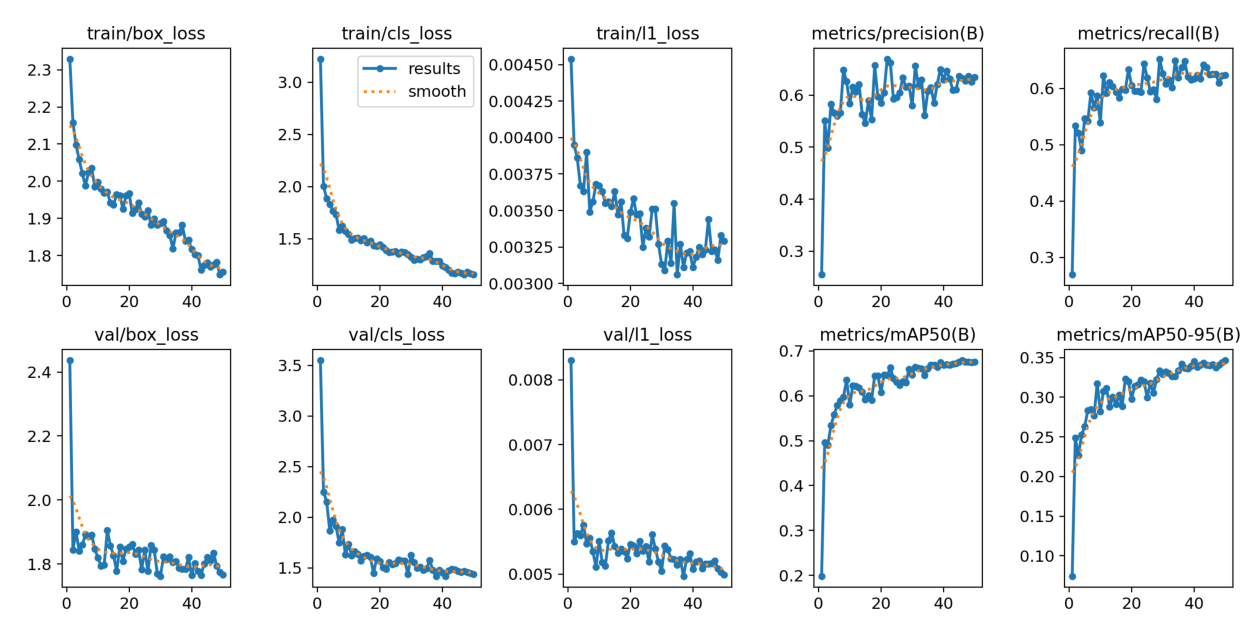

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO26s summary (fused): 120 layers, 9,466,341 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3280.6±1428.1 MB/s, size: 42.0 KB)
val: Scanning /content/cashew_yolo26/EXP-Y26S-SMALL-009/dataset/Test_400image_V6.v1i.yolo26/valid/labels.cache... 80 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80 41.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 8.4it/s 1.2s0.1s
                   all         80       2178      0.635      0.623      0.675      0.346
           anthracnose         53        676      0.543      0.555      0.574      0.249
            leaf_miner         38        109      0.599      0.688       0.71      0.418
              red_rust         26       1393      0.763      0.627      0.741      0.372
Speed: 0.6ms preprocess, 1.1ms inf

In [12]:

TRAIN_RUN_DIR = RUNS_DIR / "train" / EXPERIMENT_ID
BEST_PT = TRAIN_RUN_DIR / "weights" / "best.pt"
LAST_PT = TRAIN_RUN_DIR / "weights" / "last.pt"

assert BEST_PT.exists(), f"Không tìm thấy {BEST_PT}"

print("Best checkpoint:", BEST_PT)
print("Last checkpoint:", LAST_PT)

results_png = TRAIN_RUN_DIR / "results.png"

if results_png.exists():
    img = Image.open(results_png)
    plt.figure(figsize=(16, 10))
    plt.imshow(img)
    plt.axis("off")
    plt.show()


# Ultralytics stores rows as predicted classes and columns as true classes.
# Render the saved matrices with a light blue/white scale and black labels.
def save_readable_confusion_matrices(metrics, output_dir):
    confusion = getattr(metrics, "confusion_matrix", None)
    if confusion is None:
        raise RuntimeError("Ultralytics did not return a confusion matrix; validate with plots=True.")
    matrix = np.asarray(confusion.matrix, dtype=np.float64)
    labels = [class_names[i] for i in range(len(class_names))]
    if matrix.shape == (len(labels) + 1, len(labels) + 1):
        labels.append("background")
    elif matrix.shape != (len(labels), len(labels)):
        raise ValueError(f"Unexpected confusion matrix shape: {matrix.shape}")

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        values = matrix / np.maximum(matrix.sum(axis=0, keepdims=True), 1) if normalized else matrix
        pd.DataFrame(values, index=labels, columns=labels).to_csv(
            output_dir / f"confusion_matrix{suffix}.csv"
        )
        fig, ax = plt.subplots(figsize=(10, 8), facecolor="white")
        ax.imshow(values, cmap=MATRIX_CMAP, vmin=0, vmax=1 if normalized else max(float(values.max()), 1))
        ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
        ax.set_yticks(range(len(labels)), labels)
        ax.set_xlabel("True class")
        ax.set_ylabel("Predicted class")
        ax.set_title("Confusion Matrix" + (" Normalized" if normalized else ""))
        for row in range(len(labels)):
            for col in range(len(labels)):
                value = f"{values[row, col]:.2f}" if normalized else f"{int(values[row, col])}"
                ax.text(col, row, value, ha="center", va="center", color="black", fontsize=9)
        fig.tight_layout()
        fig.savefig(output_dir / f"confusion_matrix{suffix}.png", dpi=200, bbox_inches="tight")
        plt.close(fig)


# Re-evaluate the selected checkpoint on Validation, then replace the
# automatically styled train-run matrix figures in the exported archive.
validation_model = YOLO(str(BEST_PT))
validation_metrics = validation_model.val(
    data=str(FIXED_YAML), split="val", imgsz=IMG_SIZE, batch=BATCH_SIZE,
    device=DEVICE, workers=WORKERS, conf=0.001, iou=NMS_IOU,
    plots=True, save_json=False,
    project=str(RUNS_DIR / "validation"), name=EXPERIMENT_ID,
    exist_ok=True, verbose=True,
)
save_readable_confusion_matrices(validation_metrics, RUNS_DIR / "validation" / EXPERIMENT_ID)
save_readable_confusion_matrices(validation_metrics, TRAIN_RUN_DIR)



## 10. Đánh giá checkpoint tốt nhất trên Test set

YOLO tự tính:

- Precision
- Recall
- mAP@0.50
- mAP@0.75
- mAP@0.50:0.95
- AP theo từng class

**Không dùng các kết quả Test này để tuning model.**


In [13]:

# ============================================================
# TEST EVALUATION
# ============================================================

best_model = YOLO(str(BEST_PT))

test_metrics = best_model.val(
    data=str(FIXED_YAML),
    split="test",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    workers=WORKERS,
    conf=0.001,      # threshold thấp để xây PR curve/mAP
    iou=NMS_IOU,     # NMS IoU, KHÔNG phải mAP IoU threshold
    plots=True,
    save_json=False,
    project=str(RUNS_DIR / "test"),
    name=EXPERIMENT_ID,
    exist_ok=True,
    verbose=True,
)

save_readable_confusion_matrices(test_metrics, RUNS_DIR / "test" / EXPERIMENT_ID)
print("\nTest evaluation completed.")


Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO26s summary (fused): 120 layers, 9,466,341 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3481.4±1239.0 MB/s, size: 44.4 KB)
val: Scanning /content/cashew_yolo26/EXP-Y26S-SMALL-009/dataset/Test_400image_V6.v1i.yolo26/test/labels... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 3.8Kit/s 0.0s
val: New cache created: /content/cashew_yolo26/EXP-Y26S-SMALL-009/dataset/Test_400image_V6.v1i.yolo26/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 6.0it/s 0.8s0.2s
                   all         39       1335      0.674      0.624      0.676      0.333
           anthracnose         30        420      0.718      0.598      0.658      0.255
            leaf_miner         19         91      0.677      0.692      0.743      0.451
             

## 11. Tổng hợp Precision / Recall / F1 / mAP

In [14]:

# ============================================================
# BUILT-IN YOLO METRICS
# ============================================================

box = test_metrics.box

precision = float(box.mp)
recall = float(box.mr)
f1 = 2 * precision * recall / (precision + recall + 1e-12)

map50 = float(box.map50)
map75 = float(box.map75)
map5095 = float(box.map)

print("=" * 70)
print("YOLO TEST METRICS")
print("=" * 70)
print(f"Precision       : {precision:.4f}")
print(f"Recall          : {recall:.4f}")
print(f"F1-score        : {f1:.4f}")
print(f"mAP@0.50        : {map50:.4f}")
print(f"mAP@0.75        : {map75:.4f}")
print(f"mAP@0.50:0.95   : {map5095:.4f}")


YOLO TEST METRICS
Precision       : 0.6740
Recall          : 0.6240
F1-score        : 0.6481
mAP@0.50        : 0.6760
mAP@0.75        : 0.2831
mAP@0.50:0.95   : 0.3326


In [15]:

# ============================================================
# PER-CLASS METRICS
# ============================================================

per_class_rows = []

for class_id, class_name in enumerate(class_names):
    p, r, ap50, ap = box.class_result(class_id)
    class_f1 = 2 * p * r / (p + r + 1e-12)

    per_class_rows.append({
        "class_id": class_id,
        "class_name": class_name,
        "precision": float(p),
        "recall": float(r),
        "f1": float(class_f1),
        "mAP50": float(ap50),
        "mAP50_95": float(ap),
    })

per_class_df = pd.DataFrame(per_class_rows)
display(per_class_df)

per_class_df.to_csv(
    EXPORT_DIR / "per_class_metrics.csv",
    index=False
)


,class_id,class_name,precision,recall,f1,mAP50,mAP50_95
0,0,anthracnose,0.718108,0.597619,0.652346,0.657926,0.254663
1,1,leaf_miner,0.676521,0.692308,0.684323,0.743170,0.451434
2,2,red_rust,0.627330,0.582222,0.603935,0.626962,0.291756



## 12. Custom IoU Analysis

mAP đã sử dụng IoU trong quá trình đánh giá. Tuy nhiên, để báo cáo trực quan thêm khả năng localization, phần này tính:

- Mean IoU của các prediction match đúng;
- Median IoU;
- TP / FP / FN;
- Precision / Recall / F1 tại:
  - confidence = `PRED_CONF`
  - match IoU = `MATCH_IOU`

Quy tắc matching:

1. prediction và ground truth phải cùng class;
2. prediction được xét theo confidence giảm dần;
3. mỗi GT chỉ match tối đa một prediction;
4. IoU phải ≥ `MATCH_IOU`.


In [16]:

# ============================================================
# IOU UTILITIES
# ============================================================

def xywhn_to_xyxy(xc, yc, w, h, img_w, img_h):
    xc *= img_w
    yc *= img_h
    w *= img_w
    h *= img_h

    return np.array([
        xc - w / 2,
        yc - h / 2,
        xc + w / 2,
        yc + h / 2
    ], dtype=np.float32)

def box_iou(box_a, box_b):
    x1 = max(float(box_a[0]), float(box_b[0]))
    y1 = max(float(box_a[1]), float(box_b[1]))
    x2 = min(float(box_a[2]), float(box_b[2]))
    y2 = min(float(box_a[3]), float(box_b[3]))

    inter_w = max(0.0, x2 - x1)
    inter_h = max(0.0, y2 - y1)
    inter = inter_w * inter_h

    area_a = max(0.0, float(box_a[2] - box_a[0])) * max(0.0, float(box_a[3] - box_a[1]))
    area_b = max(0.0, float(box_b[2] - box_b[0])) * max(0.0, float(box_b[3] - box_b[1]))

    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0

def load_ground_truth(image_path):
    label_path = image_to_label_path(image_path)

    if not label_path.exists():
        return []

    with Image.open(image_path) as im:
        img_w, img_h = im.size

    text = label_path.read_text(encoding="utf-8").strip()

    if not text:
        return []

    gt = []

    for line in text.splitlines():
        parts = line.split()

        if len(parts) < 5:
            continue

        cls_id = int(float(parts[0]))
        xc, yc, w, h = map(float, parts[1:5])

        gt.append({
            "cls": cls_id,
            "box": xywhn_to_xyxy(xc, yc, w, h, img_w, img_h)
        })

    return gt

def greedy_match(gt, preds, match_iou=0.5):
    used_gt = set()
    matches = []

    preds = sorted(preds, key=lambda x: x["conf"], reverse=True)

    for pred in preds:
        best_iou = -1
        best_idx = None

        for j, target in enumerate(gt):
            if j in used_gt:
                continue

            if pred["cls"] != target["cls"]:
                continue

            iou = box_iou(pred["box"], target["box"])

            if iou > best_iou:
                best_iou = iou
                best_idx = j

        if best_idx is not None and best_iou >= match_iou:
            used_gt.add(best_idx)
            matches.append({
                "cls": pred["cls"],
                "conf": pred["conf"],
                "iou": best_iou
            })

    tp = len(matches)
    fp = len(preds) - tp
    fn = len(gt) - tp

    return matches, tp, fp, fn


In [17]:

# ============================================================
# RUN CUSTOM IOU ANALYSIS
# ============================================================

test_images = get_images(TEST_IMAGES)

prediction_results = best_model.predict(
    source=[str(p) for p in test_images],
    imgsz=IMG_SIZE,
    conf=PRED_CONF,
    iou=NMS_IOU,
    device=DEVICE,
    verbose=False,
)

all_matches = []
per_image_rows = []

total_tp = 0
total_fp = 0
total_fn = 0

per_class_counter = {
    i: {"tp": 0, "fp": 0, "fn": 0, "ious": []}
    for i in range(len(class_names))
}

for image_path, result in zip(test_images, prediction_results):
    gt = load_ground_truth(image_path)

    preds = []

    if result.boxes is not None and len(result.boxes) > 0:
        boxes_xyxy = result.boxes.xyxy.cpu().numpy()
        boxes_cls = result.boxes.cls.cpu().numpy().astype(int)
        boxes_conf = result.boxes.conf.cpu().numpy()

        for box_xyxy, cls_id, conf in zip(boxes_xyxy, boxes_cls, boxes_conf):
            preds.append({
                "cls": int(cls_id),
                "conf": float(conf),
                "box": box_xyxy.astype(np.float32)
            })

    matches, tp, fp, fn = greedy_match(
        gt,
        preds,
        match_iou=MATCH_IOU
    )

    total_tp += tp
    total_fp += fp
    total_fn += fn
    all_matches.extend(matches)

    # per-class
    for class_id in range(len(class_names)):
        gt_c = [g for g in gt if g["cls"] == class_id]
        pred_c = [p for p in preds if p["cls"] == class_id]

        m_c, tp_c, fp_c, fn_c = greedy_match(
            gt_c,
            pred_c,
            match_iou=MATCH_IOU
        )

        per_class_counter[class_id]["tp"] += tp_c
        per_class_counter[class_id]["fp"] += fp_c
        per_class_counter[class_id]["fn"] += fn_c
        per_class_counter[class_id]["ious"].extend([x["iou"] for x in m_c])

    image_ious = [m["iou"] for m in matches]

    per_image_rows.append({
        "image": image_path.name,
        "gt_boxes": len(gt),
        "pred_boxes": len(preds),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "mean_matched_iou": float(np.mean(image_ious)) if image_ious else np.nan,
    })

all_ious = [m["iou"] for m in all_matches]

custom_precision = total_tp / (total_tp + total_fp + 1e-12)
custom_recall = total_tp / (total_tp + total_fn + 1e-12)
custom_f1 = 2 * custom_precision * custom_recall / (
    custom_precision + custom_recall + 1e-12
)

mean_iou = float(np.mean(all_ious)) if all_ious else 0.0
median_iou = float(np.median(all_ious)) if all_ious else 0.0

print("=" * 70)
print("CUSTOM IOU ANALYSIS")
print("=" * 70)
print(f"Confidence threshold : {PRED_CONF}")
print(f"Match IoU threshold  : {MATCH_IOU}")
print()
print(f"TP                   : {total_tp}")
print(f"FP                   : {total_fp}")
print(f"FN                   : {total_fn}")
print()
print(f"Precision            : {custom_precision:.4f}")
print(f"Recall               : {custom_recall:.4f}")
print(f"F1-score             : {custom_f1:.4f}")
print(f"Mean IoU (TP)        : {mean_iou:.4f}")
print(f"Median IoU (TP)      : {median_iou:.4f}")


CUSTOM IOU ANALYSIS
Confidence threshold : 0.25
Match IoU threshold  : 0.5

TP                   : 739
FP                   : 307
FN                   : 596

Precision            : 0.7065
Recall               : 0.5536
F1-score             : 0.6207
Mean IoU (TP)        : 0.7443
Median IoU (TP)      : 0.7482


In [18]:

# ============================================================
# PER-CLASS CUSTOM IOU
# ============================================================

custom_class_rows = []

for class_id, class_name in enumerate(class_names):
    d = per_class_counter[class_id]

    tp = d["tp"]
    fp = d["fp"]
    fn = d["fn"]

    p = tp / (tp + fp + 1e-12)
    r = tp / (tp + fn + 1e-12)
    f1_c = 2 * p * r / (p + r + 1e-12)

    custom_class_rows.append({
        "class_id": class_id,
        "class_name": class_name,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": p,
        "recall": r,
        "f1": f1_c,
        "mean_iou_tp": float(np.mean(d["ious"])) if d["ious"] else 0.0,
        "median_iou_tp": float(np.median(d["ious"])) if d["ious"] else 0.0,
    })

custom_class_df = pd.DataFrame(custom_class_rows)
display(custom_class_df)

custom_class_df.to_csv(
    EXPORT_DIR / "custom_iou_per_class.csv",
    index=False
)

per_image_df = pd.DataFrame(per_image_rows)
per_image_df.to_csv(
    EXPORT_DIR / "custom_iou_per_image.csv",
    index=False
)


,class_id,class_name,tp,fp,fn,precision,recall,f1,mean_iou_tp,median_iou_tp
0,0,anthracnose,232,72,188,0.763158,0.552381,0.640884,0.716547,0.719062
1,1,leaf_miner,58,15,33,0.794521,0.637363,0.707317,0.827558,0.875395
2,2,red_rust,449,220,375,0.671151,0.544903,0.601474,0.747904,0.754287


### 12a. Khoảng tin cậy bootstrap theo ảnh

Với một lần train, không có cơ sở để làm kiểm định chênh lệch giữa các mô hình hoặc báo cáo p-value. Cell này lấy mẫu lại **ảnh Test** (không lấy mẫu từng box độc lập) để ước lượng khoảng tin cậy 95% cho Precision, Recall, F1 tại ngưỡng cố định `PRED_CONF`/`MATCH_IOU`. Đây là phân tích độ bất định mô tả; không dùng CI để điều chỉnh model trên Test. mAP của Ultralytics không được gán CI từ phép tính này.


,metric,point,ci_95_low,ci_95_high,method,replicates,seed,test_images,confidence_threshold,matching_iou
0,precision,0.706501,0.620792,0.786112,image-level percentile bootstrap,2000,2029,39,0.25,0.5
1,recall,0.553558,0.481278,0.637580,image-level percentile bootstrap,2000,2029,39,0.25,0.5
2,f1,0.620748,0.555889,0.676638,image-level percentile bootstrap,2000,2029,39,0.25,0.5


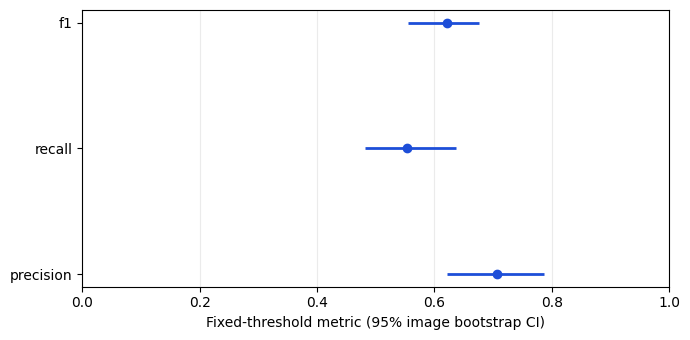

In [19]:
# Image-level bootstrap for fixed-threshold custom detection metrics.
BOOTSTRAP_REPS = 2000
BOOTSTRAP_SEED = 2029
counts = per_image_df[["tp", "fp", "fn"]].to_numpy(dtype=np.int64)
if len(counts) < 2:
    raise RuntimeError("Cần ít nhất hai ảnh Test để bootstrap")
rng = np.random.default_rng(BOOTSTRAP_SEED)
indices = rng.integers(0, len(counts), size=(BOOTSTRAP_REPS, len(counts)))
totals = counts[indices].sum(axis=1)
tp_b, fp_b, fn_b = totals[:, 0], totals[:, 1], totals[:, 2]
precision_b = np.divide(tp_b, tp_b + fp_b, out=np.zeros(BOOTSTRAP_REPS), where=(tp_b + fp_b) > 0)
recall_b = np.divide(tp_b, tp_b + fn_b, out=np.zeros(BOOTSTRAP_REPS), where=(tp_b + fn_b) > 0)
f1_b = np.divide(2 * precision_b * recall_b, precision_b + recall_b,
                 out=np.zeros(BOOTSTRAP_REPS), where=(precision_b + recall_b) > 0)
bootstrap_points = {"precision": custom_precision, "recall": custom_recall, "f1": custom_f1}
bootstrap_samples = {"precision": precision_b, "recall": recall_b, "f1": f1_b}
bootstrap_rows = []
for metric, samples in bootstrap_samples.items():
    low, high = np.quantile(samples, [0.025, 0.975])
    bootstrap_rows.append({
        "metric": metric, "point": float(bootstrap_points[metric]),
        "ci_95_low": float(low), "ci_95_high": float(high),
        "method": "image-level percentile bootstrap",
        "replicates": BOOTSTRAP_REPS, "seed": BOOTSTRAP_SEED,
        "test_images": len(counts), "confidence_threshold": PRED_CONF,
        "matching_iou": MATCH_IOU,
    })
bootstrap_df = pd.DataFrame(bootstrap_rows)
bootstrap_df.to_csv(EXPORT_DIR / "fixed_threshold_bootstrap_ci.csv", index=False)
display(bootstrap_df)

fig, ax = plt.subplots(figsize=(7, 3.5))
positions = np.arange(len(bootstrap_df))
values = bootstrap_df["point"].to_numpy()
ax.hlines(positions, bootstrap_df["ci_95_low"], bootstrap_df["ci_95_high"],
          color="#1d4ed8", linewidth=2)
ax.scatter(values, positions, color="#1d4ed8", zorder=3)
ax.set_yticks(positions, bootstrap_df["metric"])
ax.set_xlim(0, 1)
ax.set_xlabel("Fixed-threshold metric (95% image bootstrap CI)")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(EXPORT_DIR / "fixed_threshold_bootstrap_ci.png", dpi=180)
plt.show()


## 13. Xem các biểu đồ đánh giá YOLO

confusion_matrix.png


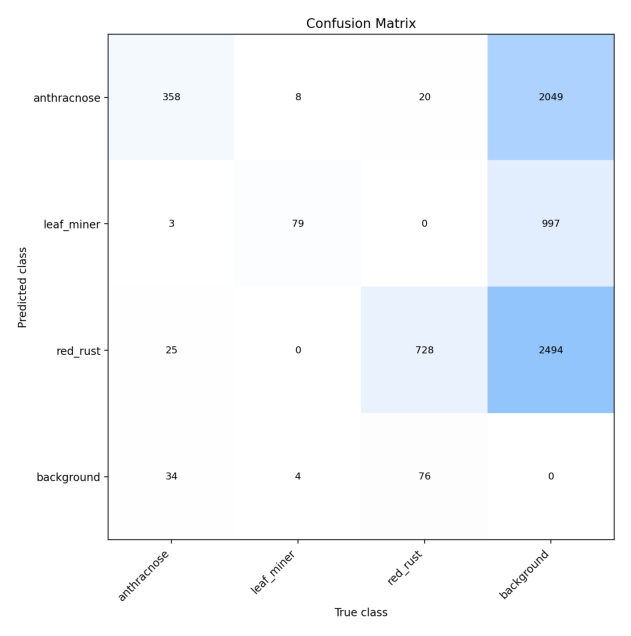

confusion_matrix_normalized.png


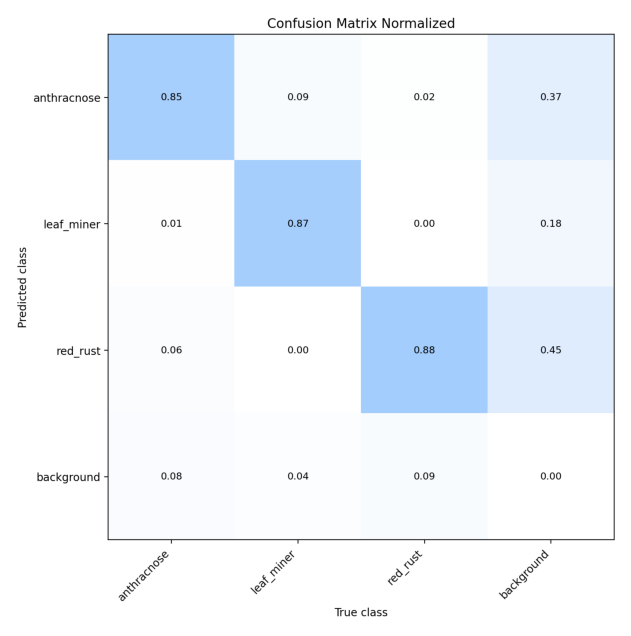

BoxPR_curve.png


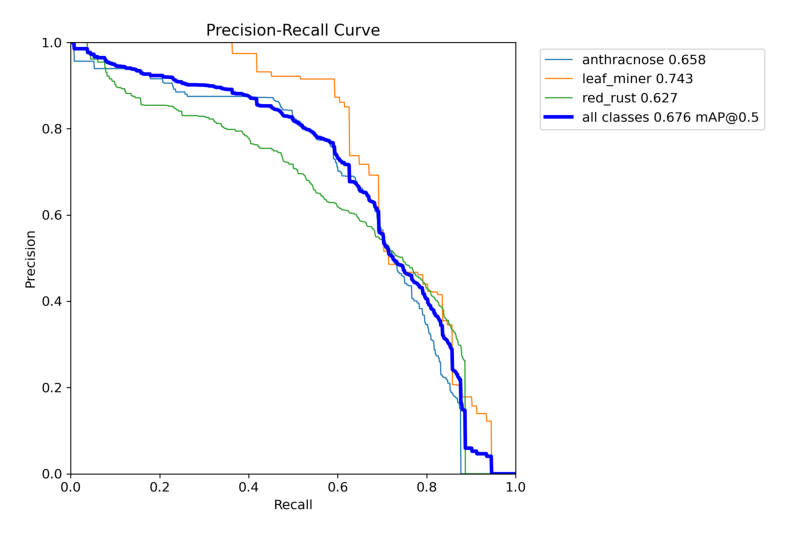

BoxF1_curve.png


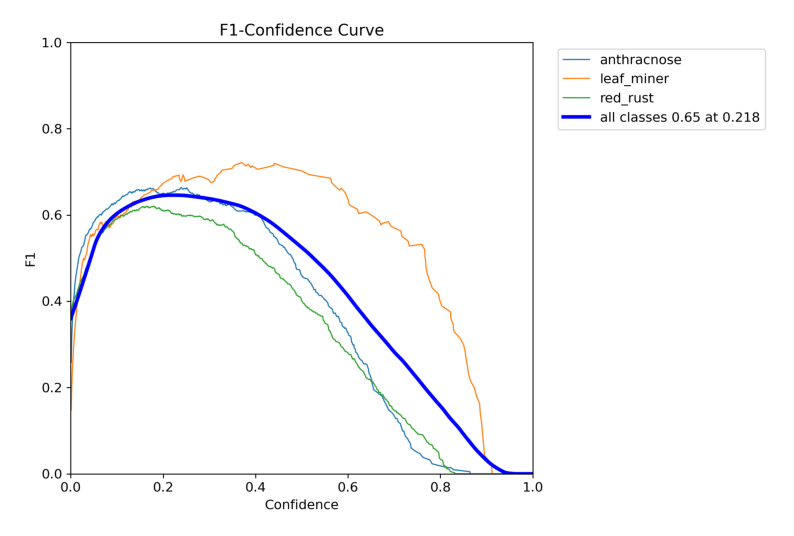

BoxP_curve.png


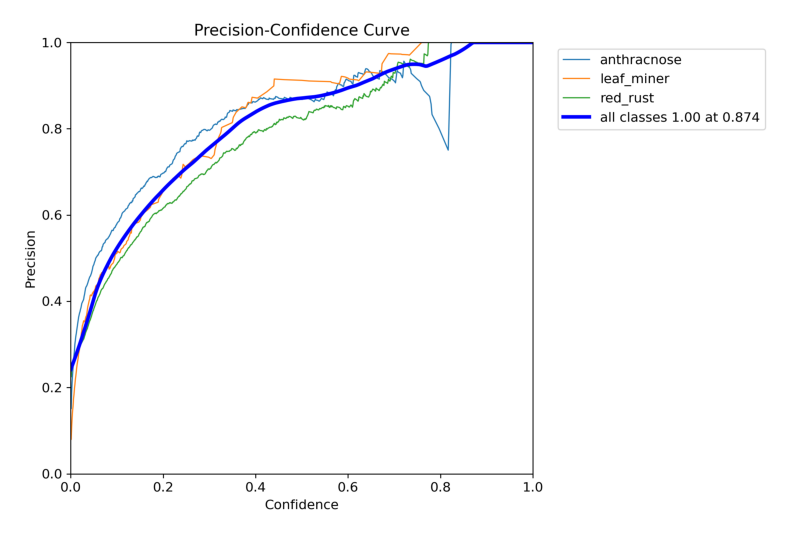

BoxR_curve.png


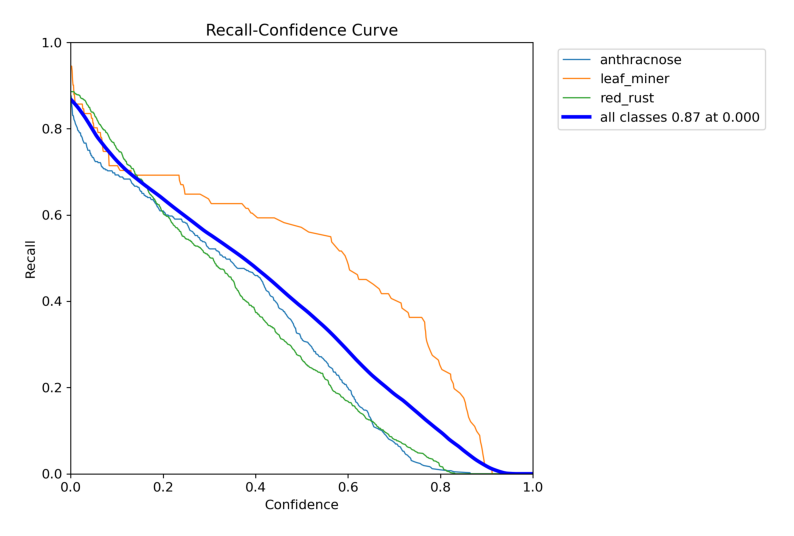

In [20]:

TEST_RUN_DIR = RUNS_DIR / "test" / EXPERIMENT_ID

plot_candidates = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
]

for filename in plot_candidates:
    p = TEST_RUN_DIR / filename

    if p.exists():
        print(filename)
        img = Image.open(p)

        plt.figure(figsize=(10, 8))
        plt.imshow(img)
        plt.axis("off")
        plt.show()


## 14. Prediction mẫu trên Test set

Results saved to /content/cashew_yolo26/EXP-Y26S-SMALL-009/export/sample_predictions/predictions


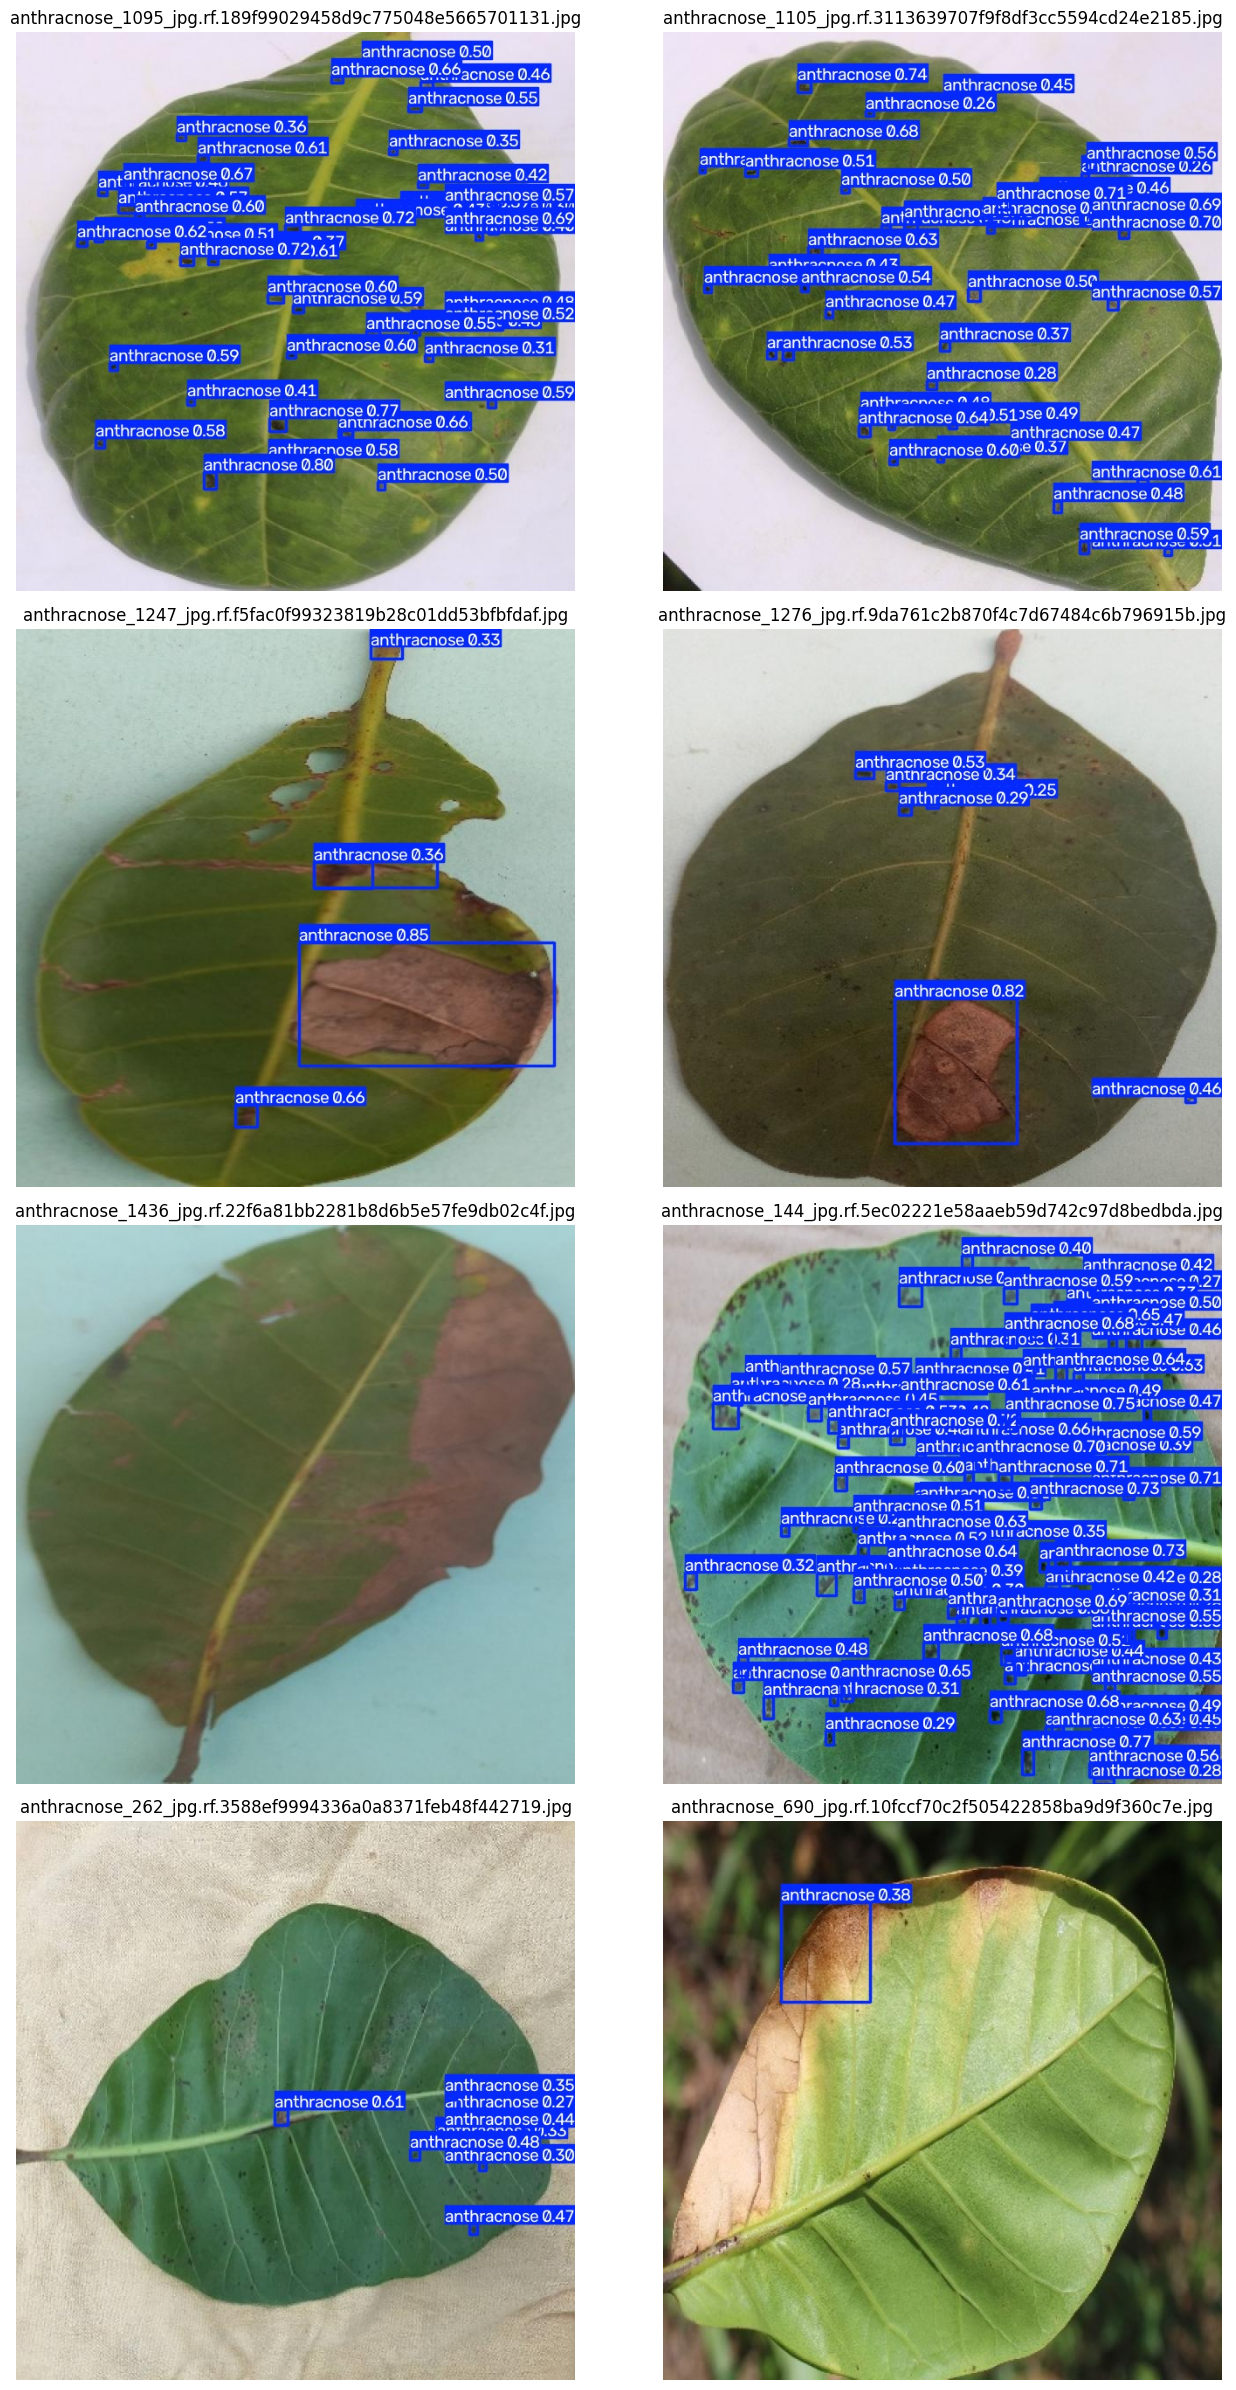

In [21]:

SAMPLE_PRED_DIR = EXPORT_DIR / "sample_predictions"
SAMPLE_PRED_DIR.mkdir(parents=True, exist_ok=True)

sample_source = [str(p) for p in test_images[:min(8, len(test_images))]]

_ = best_model.predict(
    source=sample_source,
    imgsz=IMG_SIZE,
    conf=PRED_CONF,
    iou=NMS_IOU,
    device=DEVICE,
    save=True,
    project=str(SAMPLE_PRED_DIR),
    name="predictions",
    exist_ok=True,
    verbose=False,
)

pred_folder = SAMPLE_PRED_DIR / "predictions"

pred_imgs = get_images(pred_folder)

if pred_imgs:
    cols = 2
    rows = int(np.ceil(len(pred_imgs) / cols))

    fig, axes = plt.subplots(rows, cols, figsize=(14, 6 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, p in zip(axes, pred_imgs):
        ax.imshow(Image.open(p))
        ax.set_title(p.name)
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Không tìm thấy prediction images.")


## 15. Lưu metrics và experiment config

In [22]:

# ============================================================
# SAVE FINAL METRICS
# ============================================================

metrics_summary = {
    "experiment": {
        "experiment_id": EXPERIMENT_ID,
        "model": MODEL_NAME,
        "seed": SEED,
    },
    "training_config": {
        "epochs": EPOCHS,
        "patience": PATIENCE,
        "imgsz": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "optimizer": OPTIMIZER,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "mosaic": MOSAIC,
        "mixup": MIXUP,
        "copy_paste": COPY_PASTE,
        "fliplr": FLIPLR,
    },
    "dataset": {
        "drive_file_id": DRIVE_FILE_ID,
        "zip_filename": ZIP_FILENAME,
        "drive_folder_id": DRIVE_RESULT_FOLDER_ID,
        "zip_sha256": DATASET_SHA256,
        "classes": class_names,
        "statistics": stats,
    },
    "test_yolo_metrics": {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "mAP50": map50,
        "mAP75": map75,
        "mAP50_95": map5095,
    },
    "custom_iou_analysis": {
        "prediction_confidence_threshold": PRED_CONF,
        "nms_iou": NMS_IOU,
        "matching_iou_threshold": MATCH_IOU,
        "tp": total_tp,
        "fp": total_fp,
        "fn": total_fn,
        "precision": custom_precision,
        "recall": custom_recall,
        "f1": custom_f1,
        "mean_iou_tp": mean_iou,
        "median_iou_tp": median_iou,
    },
    "fixed_threshold_bootstrap_ci": bootstrap_rows,
    "efficiency": {
        "training_time_seconds": training_time
    }
}

with open(
    EXPORT_DIR / "metrics_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics_summary, f, indent=2, ensure_ascii=False)

config_summary = {
    "dataset_zip_sha256": DATASET_SHA256,
    "drive_result_folder_id": DRIVE_RESULT_FOLDER_ID,
    "ultralytics_version": ultralytics.__version__,
    "python_version": sys.version.split()[0],
    "drive_file_id": DRIVE_FILE_ID,
    "zip_filename": ZIP_FILENAME,
    "experiment_id": EXPERIMENT_ID,
    "model": MODEL_NAME,
    "seed": SEED,
    "epochs": EPOCHS,
    "patience": PATIENCE,
    "imgsz": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "optimizer": OPTIMIZER,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "mosaic": MOSAIC,
    "mixup": MIXUP,
    "copy_paste": COPY_PASTE,
    "fliplr": FLIPLR,
    "pred_conf": PRED_CONF,
    "nms_iou": NMS_IOU,
    "match_iou": MATCH_IOU,
}

with open(
    EXPORT_DIR / "experiment_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(config_summary, f, indent=2, ensure_ascii=False)

print("Saved:", EXPORT_DIR)


Saved: /content/cashew_yolo26/EXP-Y26S-SMALL-009/export


## 16. Bảng kết quả cuối

In [23]:

summary_df = pd.DataFrame([
    ["Training time (seconds)", training_time],
    ["Training time (minutes)", training_time / 60],
    ["Precision", precision],
    ["Recall", recall],
    ["F1-score", f1],
    ["mAP@0.50", map50],
    ["mAP@0.75", map75],
    ["mAP@0.50:0.95", map5095],
    ["Mean IoU (matched TP)", mean_iou],
    ["Median IoU (matched TP)", median_iou],
    ["Custom Precision @ IoU 0.50", custom_precision],
    ["Custom Recall @ IoU 0.50", custom_recall],
    ["Custom F1 @ IoU 0.50", custom_f1],
    ["Custom F1 bootstrap CI low", bootstrap_df.loc[bootstrap_df.metric == "f1", "ci_95_low"].iloc[0]],
    ["Custom F1 bootstrap CI high", bootstrap_df.loc[bootstrap_df.metric == "f1", "ci_95_high"].iloc[0]],
], columns=["Metric", "Value"])

display(summary_df)

summary_df.to_csv(
    EXPORT_DIR / "final_summary.csv",
    index=False
)


,Metric,Value
0,Training time (seconds),130.341079
1,Training time (minutes),2.172351
2,Precision,0.673986
3,Recall,0.624050
4,F1-score,0.648057
5,mAP@0.50,0.676020
6,mAP@0.75,0.283078
7,mAP@0.50:0.95,0.332618
8,Mean IoU (matched TP),0.744311
9,Median IoU (matched TP),0.748211


## 17. Đóng gói experiment

ZIP chứa checkpoint `best.pt`/`last.pt`, log và biểu đồ Train/Test, confusion matrix, PR/F1 curves, thống kê số box theo class/split, kết quả bootstrap theo ảnh, metrics, cấu hình và dấu vân tay SHA256 của dataset. ZIP được tạo tại runtime rồi upload vào cùng thư mục Drive chứa dataset V6.


In [24]:

# Include the exact normalized dataset configuration in the archive.
shutil.copy2(FIXED_YAML, EXPORT_DIR / "data_fixed.yaml")

# Copy checkpoints vào export để dễ lấy
checkpoint_dir = EXPORT_DIR / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

if BEST_PT.exists():
    shutil.copy2(BEST_PT, checkpoint_dir / f"{EXPERIMENT_ID}_best.pt")

if LAST_PT.exists():
    shutil.copy2(LAST_PT, checkpoint_dir / f"{EXPERIMENT_ID}_last.pt")

# Copy plots/logs của train và test
if TRAIN_RUN_DIR.exists():
    shutil.copytree(
        TRAIN_RUN_DIR,
        EXPORT_DIR / "train_run",
        dirs_exist_ok=True
    )

if TEST_RUN_DIR.exists():
    shutil.copytree(
        TEST_RUN_DIR,
        EXPORT_DIR / "test_run",
        dirs_exist_ok=True
    )

ZIP_EXPORT = shutil.make_archive(
    str(WORK_ROOT / EXPERIMENT_ID),
    "zip",
    root_dir=EXPORT_DIR
)

print("=" * 70)
print("PACKAGED — run the next cell to upload to Drive")
print("=" * 70)
print("Experiment folder :", EXPORT_DIR)
print("ZIP result        :", ZIP_EXPORT)
print("Best model        :", checkpoint_dir / f"{EXPERIMENT_ID}_best.pt")




PACKAGED — run the next cell to upload to Drive
Experiment folder : /content/cashew_yolo26/EXP-Y26S-SMALL-009/export
ZIP result        : /content/cashew_yolo26/EXP-Y26S-SMALL-009.zip
Best model        : /content/cashew_yolo26/EXP-Y26S-SMALL-009/export/checkpoints/EXP-Y26S-SMALL-009_best.pt


## 18. Upload ZIP kết quả vào thư mục 400 image v6

Cell này chạy sau khi đóng gói và xác minh file ZIP trên Drive bằng kích thước + MD5. Nếu upload gián đoạn, chạy lại cell xác thực Drive và cell này trong cùng phiên Colab/Kaggle; không cần train lại.


In [25]:
# ============================================================
# UPLOAD RESULT ZIP DIRECTLY TO GOOGLE DRIVE
# ============================================================
import hashlib
from datetime import datetime, timezone
from googleapiclient.http import MediaFileUpload

archive_path = WORK_ROOT / f"{EXPERIMENT_ID}.zip"
if not archive_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy ZIP kết quả: {archive_path}")
with zipfile.ZipFile(archive_path) as archive:
    bad_member = archive.testzip()
if bad_member is not None:
    raise ValueError(f"ZIP kết quả bị lỗi tại: {bad_member}")

local_md5 = hashlib.md5()
with archive_path.open("rb") as source:
    for chunk in iter(lambda: source.read(8 * 1024 * 1024), b""):
        local_md5.update(chunk)
local_md5 = local_md5.hexdigest()

existing = drive_service.files().list(
    q=f"'{DRIVE_RESULT_FOLDER_ID}' in parents and name = '{archive_path.name}' and trashed = false",
    fields="files(id,name,size,md5Checksum,webViewLink)",
    pageSize=100,
    supportsAllDrives=True,
    includeItemsFromAllDrives=True,
).execute().get("files", [])

same_file = next((f for f in existing if f.get("md5Checksum") == local_md5), None)
if same_file:
    drive_file = same_file
    print("ZIP này đã có trên Drive:", drive_file["id"])
else:
    # Giữ kết quả cũ nếu chạy lại cùng experiment ID với nội dung khác.
    upload_name = archive_path.name
    if existing:
        timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
        upload_name = f"{archive_path.stem}_{timestamp}{archive_path.suffix}"
    media = MediaFileUpload(
        str(archive_path), mimetype="application/zip",
        chunksize=8 * 1024 * 1024, resumable=True,
    )
    request = drive_service.files().create(
        body={"name": upload_name, "parents": [DRIVE_RESULT_FOLDER_ID]},
        media_body=media,
        fields="id,name,size,md5Checksum,parents,webViewLink",
        supportsAllDrives=True,
    )
    drive_file = None
    while drive_file is None:
        progress, drive_file = request.next_chunk(num_retries=3)
        if progress is not None:
            print(f"Drive upload: {progress.progress():.0%}")

verified = drive_service.files().get(
    fileId=drive_file["id"],
    fields="id,name,size,md5Checksum,parents,webViewLink",
    supportsAllDrives=True,
).execute()
if int(verified["size"]) != archive_path.stat().st_size:
    raise RuntimeError("Drive upload có kích thước khác ZIP cục bộ")
if verified.get("md5Checksum") != local_md5:
    raise RuntimeError("Drive upload có MD5 khác ZIP cục bộ")
if DRIVE_RESULT_FOLDER_ID not in verified.get("parents", []):
    raise RuntimeError("ZIP chưa nằm trong thư mục Drive đích")

DRIVE_RESULT_URL = verified.get("webViewLink") or f"https://drive.google.com/file/d/{verified['id']}/view"
print("RESULT UPLOADED TO DRIVE:", DRIVE_RESULT_URL)


Drive upload: 10%
Drive upload: 19%
Drive upload: 29%
Drive upload: 38%
Drive upload: 48%
Drive upload: 58%
Drive upload: 67%
Drive upload: 77%
Drive upload: 87%
Drive upload: 96%
RESULT UPLOADED TO DRIVE: https://drive.google.com/file/d/1F1-iFhqMoqoGXlhWfMJp4Rc2wqoTS0Yn/view?usp=drivesdk



# Cách đọc kết quả

Trong khóa luận, với YOLO Detection nên ưu tiên báo cáo:

| Metric | Vai trò |
|---|---|
| Precision | Prediction bệnh có bao nhiêu phần đúng |
| Recall | Có phát hiện được phần lớn lesion thật hay không |
| mAP@0.50 | Khả năng detection ở IoU 0.5 |
| **mAP@0.50:0.95** | Metric chính, nghiêm ngặt hơn |
| AP per class | Kiểm tra class yếu, đặc biệt khi mất cân bằng |
| Mean IoU | Mức độ khớp vị trí box dự đoán với GT |
| Confusion Matrix | Xem class nào bị nhầm |
| PR/F1 curves | Phân tích threshold confidence |

Đối với dataset nhỏ, **không nên kết luận chỉ từ mAP tổng**. Hãy kiểm tra riêng `anthracnose`, `leaf_miner`, `red_rust`, đặc biệt class có ít annotation.
